# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: suneel kumar **
- **Student ID: 023-24-0527 **
- **Section: B **
- **GitHub:https://github.com/WadhwaniSuneel/ML1**
- **Kaggle:https://www.kaggle.com/suneelwadhwani**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [2]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.datasets import load_wine

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score
)

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")

df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

print(df.head())

print(df.shape)

print(df.isnull().sum())

print(df.duplicated().sum())

print(df["Gender"].value_counts())

print(df[["Age", "Income", "Spending"]].describe())

   CustomerID  Gender  Age  Income  Spending
0           1    Male   19      15        39
1           2    Male   21      15        81
2           3  Female   20      16         6
3           4  Female   23      16        77
4           5  Female   31      17        40
(200, 5)
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
0
Gender
Female    112
Male       88
Name: count, dtype: int64
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


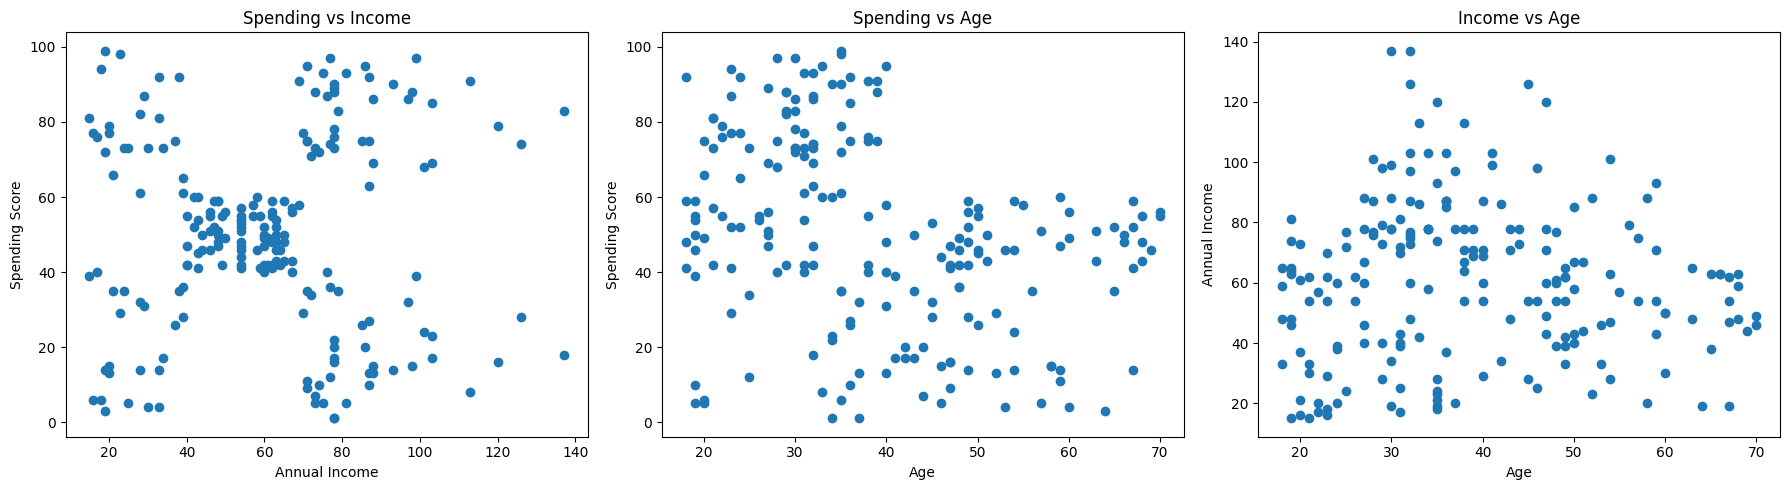

In [4]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df["Income"], df["Spending"])
axes[0].set_title("Spending vs Income")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")

axes[1].scatter(df["Age"], df["Spending"])
axes[1].set_title("Spending vs Age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score")


axes[2].scatter(df["Age"], df["Income"])
axes[2].set_title("Income vs Age")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Annual Income")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) The Spending vs Income plot shows approximately five visible groups. The Spending vs Age and Income vs Age plots show less clearly separated groups. Spending vs Income provides the clearest visual separation.

(b)K-Means is an unsupervised learning algorithm. The Mall Customers dataset does not contain predefined target labels. Therefore, we cannot compare predictions with actual labels to calculate accuracy. We also do not need a traditional train/test split. Instead, we evaluate clustering using inertia, silhouette score and visualization.



---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [5]:
# YOUR CODE HERE
X = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

centroids = np.array([4.0, 11.0])

iteration = 0

while True:
    iteration += 1

    distances = np.abs(X[:, None] - centroids[None, :])

    labels = distances.argmin(axis=1)

    new_centroids = centroids.copy()

    for k in range(2):
        cluster_points = X[labels == k]

        if len(cluster_points) > 0:
            new_centroids[k] = cluster_points.mean()

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k+1}: {X[labels == k]}")

    print("New Centroids:", new_centroids)

    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

inertia = np.sum((X - centroids[labels]) ** 2)



Iteration 1
Cluster 1: [2 4 3]
Cluster 2: [10 12 20 30 11 25]
New Centroids: [ 3. 18.]

Iteration 2
Cluster 1: [ 2  4 10  3]
Cluster 2: [12 20 30 11 25]
New Centroids: [ 4.75 19.6 ]

Iteration 3
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New Centroids: [ 7. 25.]

Iteration 4
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New Centroids: [ 7. 25.]


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [6]:
# YOUR CODE HERE
X2 = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]])
  
centroids = X2[[0, 1]].astype(float)

iteration = 0

while True:

    iteration += 1

    distances = np.sqrt(
        ((X2[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    )


    labels = distances.argmin(axis=1)

 
    new_centroids = centroids.copy()

    for k in range(2):
        cluster_points = X2[labels == k]

        if len(cluster_points) > 0:
            new_centroids[k] = cluster_points.mean(axis=0)

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k+1}:")
        for point in X2[labels == k]:
            print(point)

    print("New Centroids:")
    print(new_centroids)

    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

final_distances = np.sqrt(
    ((X2[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
)

print("\nFinal Centroids:")
print(centroids)

print("\nFinal Distance Table:")
print(final_distances)

print("\nFinal Labels:")
print(labels)


Iteration 1
Cluster 1:
[185  72]
[179  68]
[182  72]
[188  77]
Cluster 2:
[170  56]
[168  60]
New Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster 1:
[185  72]
[179  68]
[182  72]
[188  77]
Cluster 2:
[170  56]
[168  60]
New Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final Distance Table:
[[ 1.52069063 21.26029163]
 [21.12610944  2.23606798]
 [19.7563281   2.23606798]
 [ 6.1897092  14.14213562]
 [ 1.52069063 19.10497317]
 [ 6.54312616 26.87005769]]

Final Labels:
[0 1 1 0 0 0]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [7]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):

    X = np.array(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float)

    K = len(centroids)

    for iteration in range(1, max_iter + 1):
        distances = np.sqrt(
            ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        )
        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()

        for k in range(K):
            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)


        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.sqrt(
        ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    )

    labels = distances.argmin(axis=1)

    inertia = np.sum(
        (X - centroids[labels]) ** 2
    )

    return labels, centroids, inertia, iteration

In [8]:
# YOUR CODE HERE
X = np.array([[2], [4], [10], [12], [3],[20], [30], [11], [25]])

initial_centroids = np.array([[4],[11]])

labels, final_centroids, inertia, iterations = my_kmeans(X,initial_centroids)

print("Final Labels:", labels)

print("Final Centroids:")
print(final_centroids)

print("Inertia:", inertia)

print("Iterations:", iterations)

Final Labels: [0 0 0 0 0 1 1 0 1]
Final Centroids:
[[ 7.]
 [25.]]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [9]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].values

initial_centroids = X2[:5].copy()

my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2,
    initial_centroids
)

print("Custom K-Means Results")

print("Iterations:", my_iterations)

print("Inertia:", my_inertia)

print("Centroids:")
print(my_centroids)

sk_model = KMeans(n_clusters=5,init=initial_centroids,n_init=1,tol=0,algorithm="lloyd")

sk_model.fit(X2)

print("\nScikit-learn Results")

print("Iterations:", sk_model.n_iter_)

print("Inertia:", sk_model.inertia_)

print("Centroids:")
print(sk_model.cluster_centers_)

Custom K-Means Results
Iterations: 4
Inertia: 44448.45544793371
Centroids:
[[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

Scikit-learn Results
Iterations: 4
Inertia: 44448.4554479337
Centroids:
[[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]


In [10]:
print("\nComparison")

print("Custom Iterations:", my_iterations)
print("Sklearn Iterations:", sk_model.n_iter_)

print("\nCustom Inertia:", my_inertia)
print("Sklearn Inertia:", sk_model.inertia_)

print("\nLabels Match:",
      np.array_equal(my_labels, sk_model.labels_))

print("\nCentroids Match:",
      np.allclose(my_centroids, sk_model.cluster_centers_))

print("\nInertia Match:",
      np.isclose(my_inertia, sk_model.inertia_))


Comparison
Custom Iterations: 4
Sklearn Iterations: 4

Custom Inertia: 44448.45544793371
Sklearn Inertia: 44448.4554479337

Labels Match: True

Centroids Match: True

Inertia Match: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a)Initially, the centroids were 4 and 11. The point 10
was closer to centroid 11, so it belonged to C2.

After the first iteration, the new centroids became
3 and 18. Now the distance of 10 from centroid 3
was 7, while its distance from centroid 18 was 8.

Therefore, point 10 moved to C1 in iteration 2

(b) The loop stops when the centroids no longer change.
We use np.allclose() to check convergence.

K-Means repeatedly improves or maintains the clustering
objective and has a finite number of possible assignments.
However, it can reach a local optimum rather than the
global optimum. Therefore, the final result is not
necessarily the best possible clustering.

(c) Yes, my custom K-Means function produced the same
labels, centroids and inertia as Scikit-learn.
Both implementations used the same initial centroids
and Lloyd's algorithm.

(d) A centroid represents the average position of all
customers in a cluster. For example, it represents
the average income and spending score of that group.

Features must be numeric because K-Means calculates
Euclidean distances and means. These mathematical
operations cannot directly work on categorical text.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


In [11]:
# YOUR CODE HERE
results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)

    labels = model.fit_predict(X2)

    inertia = model.inertia_

    sil_score = silhouette_score(X2, labels)

    results.append({"K": k, "Inertia": inertia, "Silhouette": sil_score})

results_df = pd.DataFrame(results)

print("K-Means Evaluation Results:")
print(results_df.round(3))

best_k = results_df.loc[results_df["Silhouette"].idxmax(), "K"]
print("\nBest K according to Silhouette:", best_k)

K-Means Evaluation Results:
    K     Inertia  Silhouette
0   2  181363.596       0.297
1   3  106348.373       0.468
2   4   73679.789       0.493
3   5   44448.455       0.554
4   6   37233.815       0.540
5   7   30241.344       0.529
6   8   25036.418       0.455
7   9   21916.795       0.456
8  10   20072.071       0.441

Best K according to Silhouette: 5


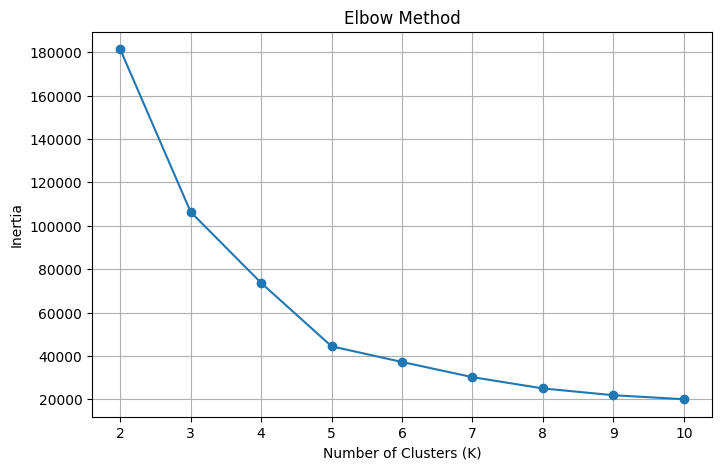

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

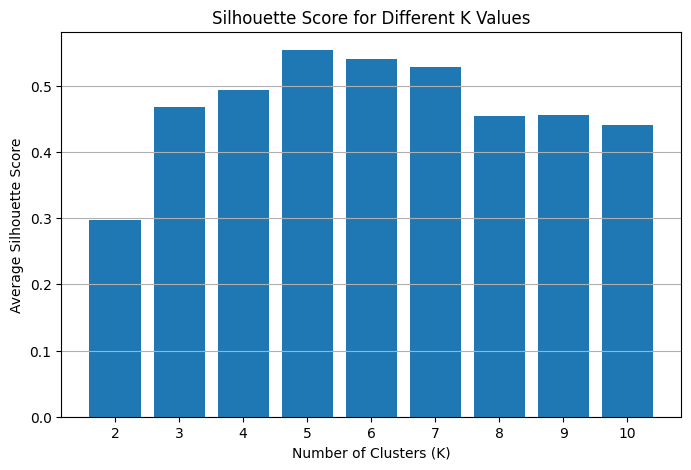

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["K"],
    results_df["Silhouette"]
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(axis="y")

plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [14]:
# YOUR CODE HERE
kmeans5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)

labels5 = kmeans5.fit_predict(X2)

sil_values = silhouette_samples(X2, labels5)

avg_sil = silhouette_score(X2, labels5)

print("Average Silhouette:", avg_sil)
print("First 10 Silhouette Values:", sil_values[:10])

Average Silhouette: 0.553931997444648
First 10 Silhouette Values: [0.41700493 0.69637752 0.6399526  0.6964831  0.39230007 0.6981303
 0.64910316 0.65972193 0.63021343 0.66350398]


In [15]:
# YOUR CODE HERE
def manual_silhouette(X, labels, point_index):
    point = X[point_index]

    own_cluster = labels[point_index]

    distances = np.linalg.norm(X - point, axis=1)

    same_mask = labels == own_cluster

    same_mask[point_index] = False

    if same_mask.sum() == 0:
        return 0.0, 0.0, 0.0

    a = distances[same_mask].mean()

    other_cluster_distances = []

    for cluster in np.unique(labels):
        if cluster != own_cluster:
            cluster_mask = labels == cluster

            mean_distance = distances[cluster_mask].mean()

            other_cluster_distances.append(mean_distance)


    b = min(other_cluster_distances)

    s = (b - a) / max(a, b)

    return a, b, s

In [16]:
a, b, s = manual_silhouette(X2, labels5, 0)

print("Customer 1 Results")

print("a:", a)
print("b:", b)
print("Manual Silhouette:", s)

print("Sklearn Silhouette:", sil_values[0])

print("Results Match:",
      np.isclose(s, sil_values[0]))

Customer 1 Results
a: 24.64044215163639
b: 42.26526678748377
Manual Silhouette: 0.41700493041881637
Sklearn Silhouette: 0.4170049304188163
Results Match: True


In [17]:

silhouette_summary = []

for cluster in np.unique(labels5):
    cluster_sil = sil_values[labels5 == cluster]
    silhouette_summary.append({"Cluster": cluster,"Count": len(cluster_sil),"Mean Silhouette": cluster_sil.mean(),"Minimum Silhouette": cluster_sil.min()})

silhouette_df = pd.DataFrame(silhouette_summary)

print("Cluster-wise Silhouette Summary:")
print(silhouette_df.round(3))

negative_count = np.sum(sil_values < 0)

print("\nCustomers with Negative Silhouette:", negative_count)

Cluster-wise Silhouette Summary:
   Cluster  Count  Mean Silhouette  Minimum Silhouette
0        0     81            0.597               0.115
1        1     39            0.509               0.225
2        2     22            0.599               0.051
3        3     35            0.504              -0.023
4        4     23            0.512              -0.009

Customers with Negative Silhouette: 2


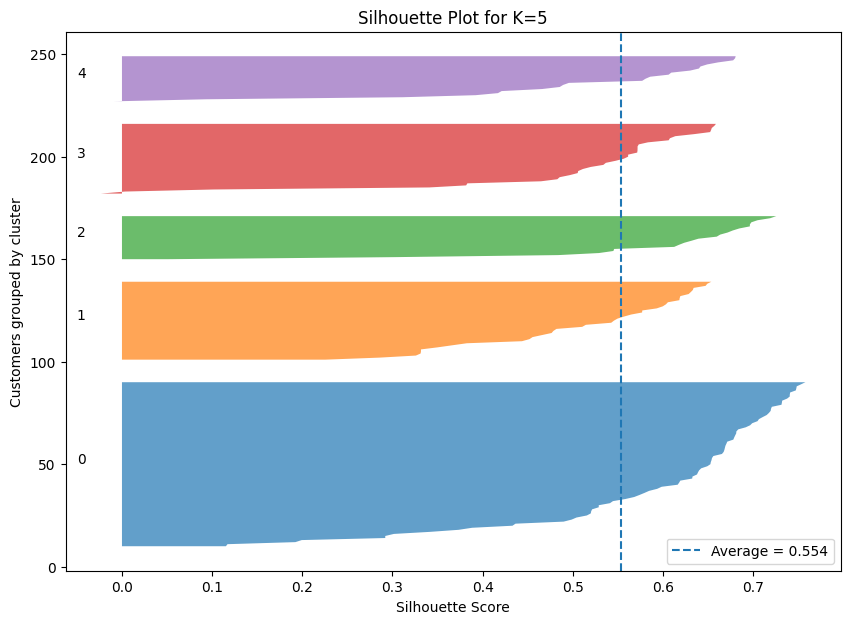

In [18]:
plt.figure(figsize=(10, 7))

y_lower = 10

for cluster in np.unique(labels5):
    cluster_sil = sil_values[labels5 == cluster]
    cluster_sil.sort()
    cluster_size = len(cluster_sil)

    y_upper = y_lower + cluster_size

    plt.fill_betweenx(np.arange(y_lower, y_upper),0,cluster_sil,alpha=0.7)
    plt.text(-0.05,y_lower + cluster_size / 2,str(cluster))
    y_lower = y_upper + 10


plt.axvline(avg_sil,linestyle="--",label=f"Average = {avg_sil:.3f}")

plt.xlabel("Silhouette Score")
plt.ylabel("Customers grouped by cluster")
plt.title("Silhouette Plot for K=5")
plt.legend()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [19]:
# YOUR CODE HERE
practice_X = np.array([[1], [3], [5], [7], [11], [13], [15]])

practice_centroids = np.array([[1], [11]])

practice_labels, practice_final_centroids, practice_inertia, practice_iterations = my_kmeans(practice_X,practice_centroids)

print("Final Clusters:")

for k in range(2):
    print(f"Cluster {k+1}:",practice_X[practice_labels == k].flatten())

print("\nFinal Centroids:")
print(practice_final_centroids)

print("\nInertia:", practice_inertia)

print("Iterations:", practice_iterations)

Final Clusters:
Cluster 1: [1 3 5 7]
Cluster 2: [11 13 15]

Final Centroids:
[[ 4.]
 [13.]]

Inertia: 28.0
Iterations: 3


In [20]:
practice_sil_values = silhouette_samples(practice_X,practice_labels)

selected_points = [1, 7, 11]

for point in selected_points:
    index = np.where(practice_X.flatten() == point)[0][0]

    a, b, s = manual_silhouette(practice_X,practice_labels,index)

    print(f"\nPoint: {point}")

    print("a:", a)
    print("b:", b)
    print("Manual Silhouette:", s)

    print("Sklearn Silhouette:",practice_sil_values[index])


Point: 1
a: 4.0
b: 12.0
Manual Silhouette: 0.6666666666666666
Sklearn Silhouette: 0.6666666666666666

Point: 7
a: 4.0
b: 6.0
Manual Silhouette: 0.3333333333333333
Sklearn Silhouette: 0.3333333333333333

Point: 11
a: 3.0
b: 7.0
Manual Silhouette: 0.5714285714285714
Sklearn Silhouette: 0.5714285714285714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow method suggests K = [your observed value]
because the reduction in inertia becomes smaller after
that point.

The silhouette method suggests K = [best_k] because
it has the highest average silhouette score.

The two methods [agree/do not agree] on the number
of clusters.

(b) Customer 1 has a silhouette score of [your value].
This indicates how well the customer fits its assigned
cluster.

Cluster [your cluster] has the weakest average
silhouette, with a mean of [your value].

There are [your count] customers with negative
silhouette scores.

(c) Point 7 is less well placed than point 1.

Point 1 has a silhouette score of approximately 0.667,
while point 7 has a score of approximately 0.333.

Point 7 is closer to its own cluster boundary because
its average distance to the nearest other cluster is
only 6, compared with 12 for point 1. 

(d) Inertia always decreases or stays the same when K
increases. If we choose K only by the lowest inertia,
we may end up creating too many clusters.

For example, when every data point has its own cluster,
inertia becomes zero, but this is not useful
segmentation.

Therefore, we should consider the Elbow Method,
Silhouette Score and practical interpretation.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


In [21]:
# YOUR CODE HERE
settings = [
    ("Random, n_init=1", "random", 1),
    ("K-Means++, n_init=1", "k-means++", 1),
    ("K-Means++, n_init=10", "k-means++", 10)
]

all_results = []

for setting_name, init_method, n_init_value in settings:

    for seed in range(30):
        model = KMeans(n_clusters=5,init=init_method,n_init=n_init_value,random_state=seed)

        labels = model.fit_predict(X2)

        all_results.append({
            "Setting": setting_name,
            "Seed": seed,
            "Inertia": model.inertia_,
            "Labels": labels,
            "Centroids": model.cluster_centers_
        })

print("Total runs:", len(all_results))

Total runs: 90


In [22]:
summary = []

for setting_name, init_method, n_init_value in settings:

    run_inertias = [
        result["Inertia"]
        for result in all_results
        if result["Setting"] == setting_name
    ]

    rounded_inertias = np.round(run_inertias, 1)

    best_inertia = min(run_inertias)
    worst_inertia = max(run_inertias)

    best_percentage = (
        np.sum(rounded_inertias == round(best_inertia, 1))/ len(run_inertias)) * 100

    summary.append({
        "Setting": setting_name,
        "Distinct Inertia Values": len(np.unique(rounded_inertias)),
        "Lowest Inertia": best_inertia,
        "Highest Inertia": worst_inertia,
        "Best Runs (%)": best_percentage
    })

summary_df = pd.DataFrame(summary)

print(summary_df.round(2))

                Setting  Distinct Inertia Values  Lowest Inertia  \
0      Random, n_init=1                       14        44448.46   
1   K-Means++, n_init=1                        6        44448.46   
2  K-Means++, n_init=10                        1        44448.46   

   Highest Inertia  Best Runs (%)  
0         91761.98          33.33  
1         66733.44          60.00  
2         44448.46         100.00  


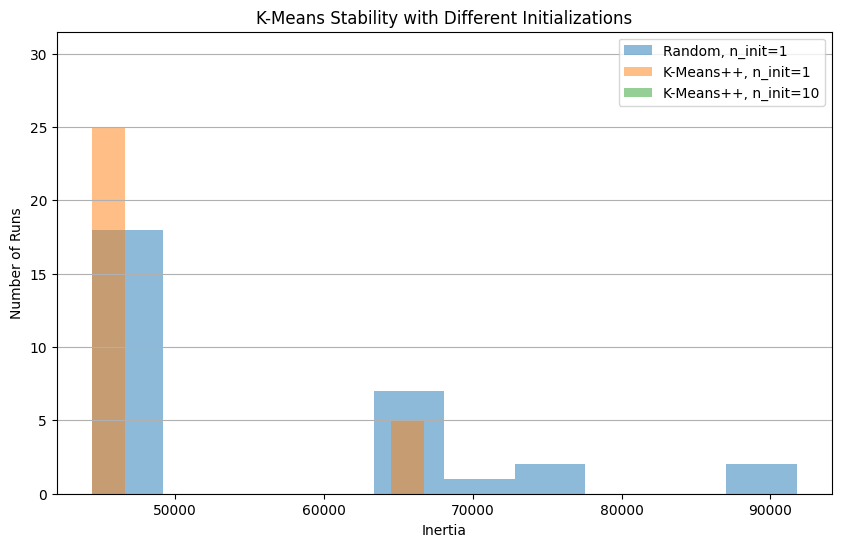

In [23]:
plt.figure(figsize=(10, 6))

for setting_name, init_method, n_init_value in settings:

    run_inertias = [
        result["Inertia"]
        for result in all_results
        if result["Setting"] == setting_name
    ]

    plt.hist(
        run_inertias,
        bins=10,
        alpha=0.5,
        label=setting_name
    )

plt.xlabel("Inertia")
plt.ylabel("Number of Runs")
plt.title("K-Means Stability with Different Initializations")
plt.legend()
plt.grid(axis="y")
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


In [24]:
# YOUR CODE HERE
random_runs = [
    result
    for result in all_results
    if result["Setting"] == "Random, n_init=1"
]

best_run = min(random_runs, key=lambda x: x["Inertia"])
worst_run = max(random_runs, key=lambda x: x["Inertia"])

print("Best Run Inertia:", best_run["Inertia"])
print("Worst Run Inertia:", worst_run["Inertia"])

Best Run Inertia: 44448.4554479337
Worst Run Inertia: 91761.97619211904


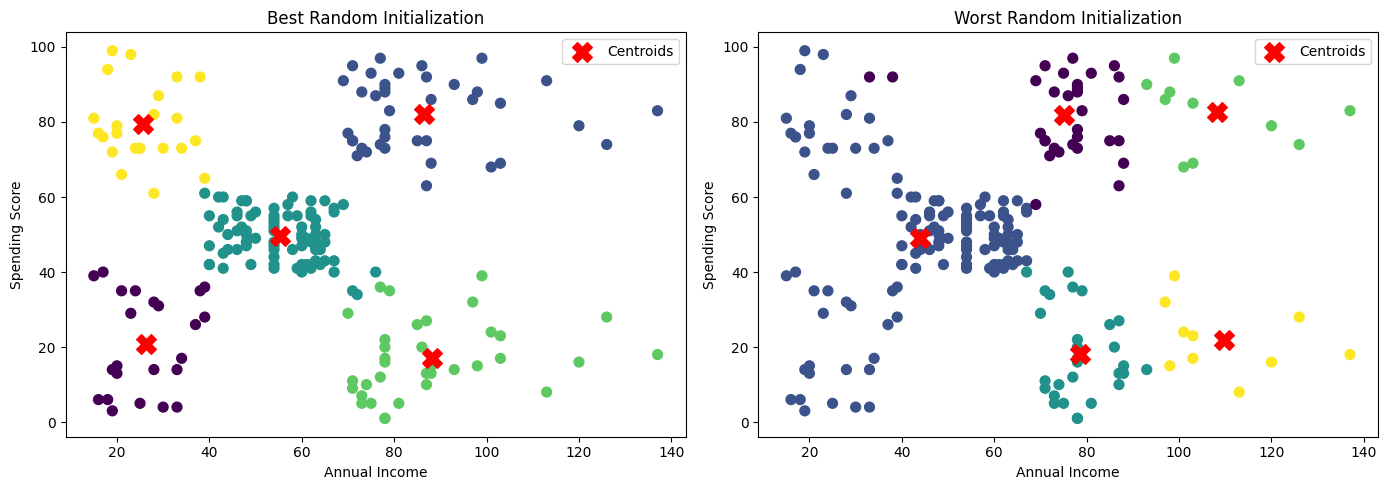

In [25]:
# Plot best and worst clustering side by side

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

runs = [
    (best_run, "Best Random Initialization"),
    (worst_run, "Worst Random Initialization")
]

for ax, (run, title) in zip(axes, runs):

    ax.scatter(
        X2[:, 0],
        X2[:, 1],
        c=run["Labels"],
        cmap="viridis",
        s=50
    )

    ax.scatter(
        run["Centroids"][:, 0],
        run["Centroids"][:, 1],
        marker="X",
        color="red",
        s=200,
        label="Centroids"
    )

    ax.set_xlabel("Annual Income")
    ax.set_ylabel("Spending Score")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

In [26]:
ari = adjusted_rand_score(
    best_run["Labels"],
    worst_run["Labels"]
)

print("Best Run Inertia:", best_run["Inertia"])
print("Worst Run Inertia:", worst_run["Inertia"])
print("ARI:", ari)

Best Run Inertia: 44448.4554479337
Worst Run Inertia: 91761.97619211904
ARI: 0.45525713010305063


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random initialization with n_init=1 produced ___ distinct inertia values, and ___% of its runs reached the best inertia. K-Means++ with n_init=1 produced ___ distinct values, while K-Means++ with n_init=10 produced ___ distinct values. The results show that ______ was more consistent 

(b) Because K-Means starts with initial centroids. Different starting centroids can cause different points to be assigned to different clusters. This can lead the algorithm to different local minima and different final inertia values.

(c) K-Means++ selects better-spread initial centroids, which can reduce poor starting configurations. Increasing n_init runs K-Means multiple times with different initializations and keeps the run with the lowest inertia.

For the last sentence, use your summary_df results to report how many distinct inertia values and what percentage of runs reached the best result

(d) Cluster numbers are arbitrary. One run might call a group Cluster 0, while another calls the same group Cluster 3. ARI compares the actual grouping of data points rather than the numerical cluster labels.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


In [27]:
# YOUR CODE HERE
X_age_income = df[["Age", "Income"]].values

X_raw_k = X_age_income.copy()

X_raw_dollars = X_age_income.copy()
X_raw_dollars[:, 1] = X_raw_dollars[:, 1] * 1000

scaler_k = StandardScaler()
X_scaled_k = scaler_k.fit_transform(X_raw_k)

scaler_dollars = StandardScaler()
X_scaled_dollars = scaler_dollars.fit_transform(X_raw_dollars)

print("Original data shape:", X_raw_k.shape)
print("Income in thousands:", X_raw_k[:5, 1])
print("Income in dollars:", X_raw_dollars[:5, 1])
print("Scaled data sample:")
print(X_scaled_k[:5])

Original data shape: (200, 2)
Income in thousands: [15 15 16 16 17]
Income in dollars: [15000 15000 16000 16000 17000]
Scaled data sample:
[[-1.42456879 -1.73899919]
 [-1.28103541 -1.73899919]
 [-1.3528021  -1.70082976]
 [-1.13750203 -1.70082976]
 [-0.56336851 -1.66266033]]


In [28]:
model_raw_k = KMeans(n_clusters=4,n_init=10,random_state=SEED)

model_raw_dollars = KMeans(n_clusters=4,n_init=10,random_state=SEED)

model_scaled_k = KMeans(n_clusters=4,n_init=10,random_state=SEED)

model_scaled_dollars = KMeans(n_clusters=4,n_init=10,random_state=SEED)

labels_raw_k = model_raw_k.fit_predict(X_raw_k)

labels_raw_dollars = model_raw_dollars.fit_predict(X_raw_dollars)

labels_scaled_k = model_scaled_k.fit_predict(X_scaled_k)

labels_scaled_dollars = model_scaled_dollars.fit_predict(X_scaled_dollars)

print("All four models trained successfully.")

All four models trained successfully.


In [29]:
ari_raw = adjusted_rand_score(labels_raw_k,labels_raw_dollars)

ari_scaled = adjusted_rand_score(labels_scaled_k,labels_scaled_dollars)

ari_raw_scaled = adjusted_rand_score(labels_raw_dollars,labels_scaled_dollars)

print("Raw k$ vs Raw dollars ARI:", ari_raw)
print("Scaled k$ vs Scaled dollars ARI:", ari_scaled)
print("Raw dollars vs Scaled dollars ARI:", ari_raw_scaled)

Raw k$ vs Raw dollars ARI: 0.48965682118947657
Scaled k$ vs Scaled dollars ARI: 1.0
Raw dollars vs Scaled dollars ARI: 0.36045266264603926


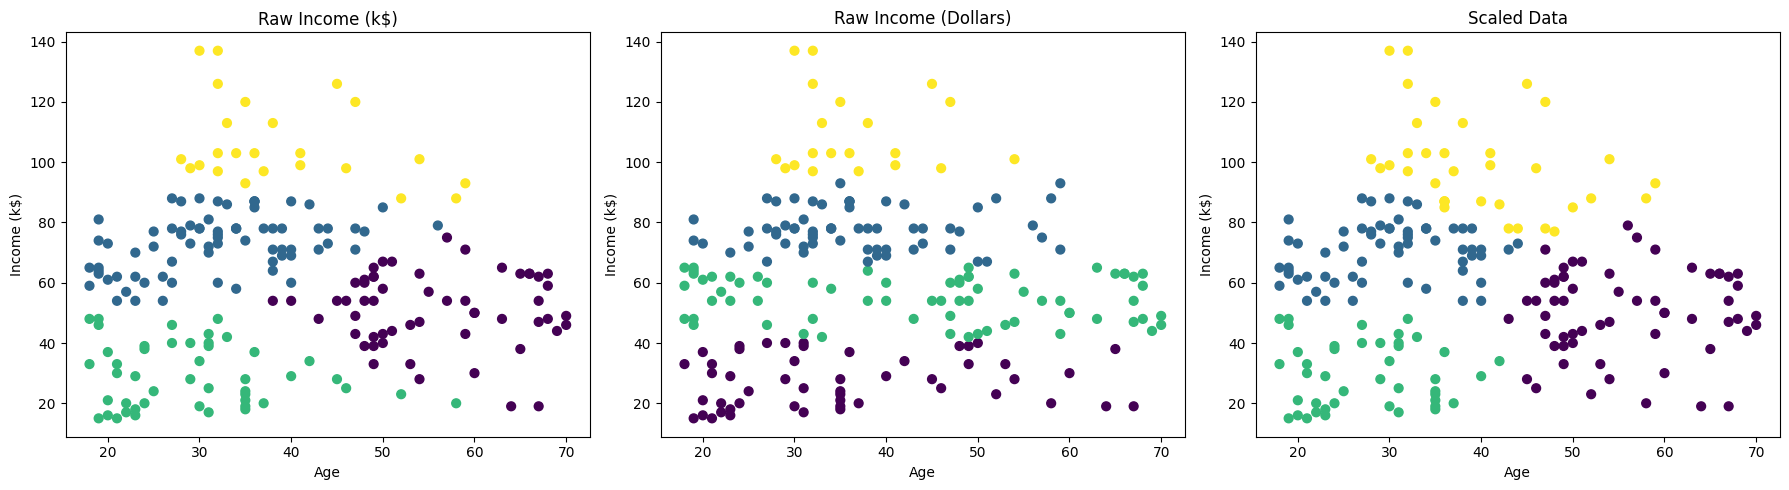

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_data = [(labels_raw_k, "Raw Income (k$)"),(labels_raw_dollars, "Raw Income (Dollars)"),(labels_scaled_k, "Scaled Data")]

for ax, (labels, title) in zip(axes, plot_data):
    ax.scatter(X_raw_k[:, 0],X_raw_k[:, 1],c=labels,cmap="viridis",s=40)

    ax.set_xlabel("Age")
    ax.set_ylabel("Income (k$)")
    ax.set_title(title)

plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [31]:
# YOUR CODE HERE
wine = load_wine()

X_wine = wine.data
y_wine = wine.target

print("Dataset shape:", X_wine.shape)
print("Number of features:", len(wine.feature_names))
print("Number of true cultivars:", len(np.unique(y_wine)))

feature_std = pd.Series(
    X_wine.std(axis=0),
    index=wine.feature_names
)

print("Three largest standard deviations:")
print(feature_std.sort_values(ascending=False).head(3))

print("\nSmallest standard deviation:")
print(feature_std.sort_values().head(1))

Dataset shape: (178, 13)
Number of features: 13
Number of true cultivars: 3
Three largest standard deviations:
proline              314.021657
magnesium             14.242308
alcalinity_of_ash      3.330170
dtype: float64

Smallest standard deviation:
nonflavanoid_phenols    0.124103
dtype: float64


In [32]:
# YOUR CODE HERE
wine_scaler = StandardScaler()

X_wine_scaled = wine_scaler.fit_transform(X_wine)

print("Original sample:")
print(X_wine[0])

print("\nScaled sample:")
print(X_wine_scaled[0]) 


wine_model_raw = KMeans(n_clusters=3,n_init=10,random_state=SEED)

wine_labels_raw = wine_model_raw.fit_predict(X_wine)

wine_model_scaled = KMeans(n_clusters=3,n_init=10,random_state=SEED)

wine_labels_scaled = wine_model_scaled.fit_predict(X_wine_scaled)

Original sample:
[1.423e+01 1.710e+00 2.430e+00 1.560e+01 1.270e+02 2.800e+00 3.060e+00
 2.800e-01 2.290e+00 5.640e+00 1.040e+00 3.920e+00 1.065e+03]

Scaled sample:
[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
  1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
  1.01300893]


In [33]:
ari_raw_wine = adjusted_rand_score(y_wine,wine_labels_raw)

ari_scaled_wine = adjusted_rand_score(y_wine,wine_labels_scaled)

sil_raw_wine = silhouette_score(X_wine,wine_labels_raw)

sil_scaled_wine = silhouette_score(X_wine_scaled,wine_labels_scaled)

print("RAW WINE DATA")
print("ARI:", ari_raw_wine)
print("Silhouette:", sil_raw_wine)
print("Cluster sizes:", np.bincount(wine_labels_raw))


print("\nSCALED WINE DATA")
print("ARI:", ari_scaled_wine)
print("Silhouette:", sil_scaled_wine)
print("Cluster sizes:", np.bincount(wine_labels_scaled))

RAW WINE DATA
ARI: 0.37111371823084754
Silhouette: 0.5711381937868838
Cluster sizes: [62 47 69]

SCALED WINE DATA
ARI: 0.8974949815093207
Silhouette: 0.2848589191898987
Cluster sizes: [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


PCA data shape: (178, 2)
Explained variance ratio:
[0.36198848 0.1920749 ]


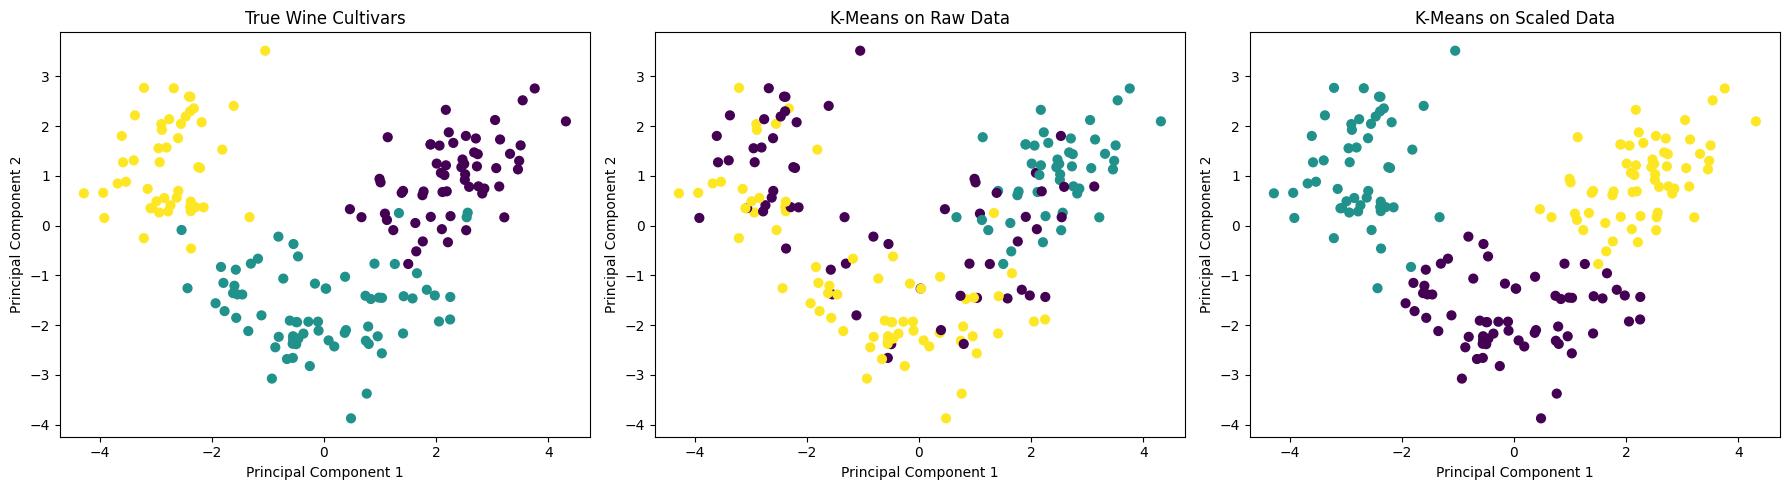

In [34]:
# YOUR CODE HERE
pca = PCA(n_components=2)

X_wine_pca = pca.fit_transform(X_wine_scaled)

print("PCA data shape:", X_wine_pca.shape)
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_results = [(y_wine, "True Wine Cultivars"),(wine_labels_raw, "K-Means on Raw Data"),(wine_labels_scaled, "K-Means on Scaled Data")]

for ax, (labels, title) in zip(axes, plot_results):
    ax.scatter(X_wine_pca[:, 0],X_wine_pca[:, 1],c=labels,cmap="viridis",s=40)

    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Changing Income from thousands to dollars changed the numerical scale of that feature. Since K-Means uses Euclidean distance, Income dominated the distance calculation when expressed in dollars.

The distance formula is:
\[
d=\sqrt{(Age_1-Age_2)^2+(Income_1-Income_2)^2}
\]

When Income is multiplied by 1000, its squared difference becomes 1,000,000 times larger. This can change the cluster assignments.

After StandardScaler, the results should become equivalent because both features are standardized independently.

(b) The feature with the largest standard deviation was ______, with a standard deviation of ______. It had a much larger numerical scale than the other features, so it strongly influenced raw Euclidean distance. The ARI was ______ for raw data and ______ for scaled data.

(c) Silhouette measures how well-separated clusters are in the feature space used for clustering. It does not check whether the clusters match the actual grape cultivars.

In raw Wine data, features with larger numerical scales can dominate the distances. K-Means may create geometrically separated clusters based mainly on those features, producing a high silhouette score without matching the true cultivars.

Comparing raw and scaled silhouette scores is not a fair direct comparison because the distance geometry changes after scaling. ARI provides an external check against the known cultivar labels.

(d) I will inspect the units, ranges, and standard deviations of the numerical features. If features have substantially different scales and should contribute comparably to distance, I will apply StandardScaler and compare clustering quality using inertia, silhouette, and domain knowledge.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [35]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].values

outlier = np.array([[400, 99]])

X_with_outlier = np.vstack([X2, outlier])

print("Original dataset shape:", X2.shape)
print("Dataset with outlier:", X_with_outlier.shape)


Original dataset shape: (200, 2)
Dataset with outlier: (201, 2)


Cluster sizes WITHOUT outlier:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster sizes WITH outlier:
0    100
1      1
2     23
3     39
4     38
Name: count, dtype: int64

Original centroids (sorted by Income):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]

Centroids with outlier (sorted by Income):
[[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]

ARI between original and outlier clustering: 0.7532040415286123


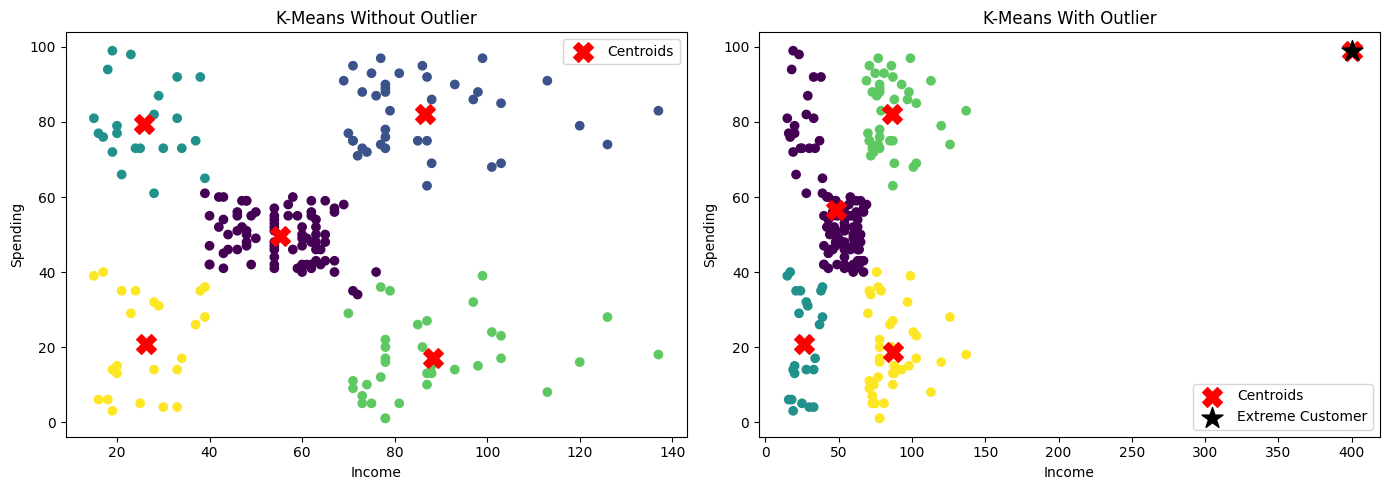

In [36]:
# YOUR CODE HERE

model_original = KMeans(n_clusters=5,n_init=10,random_state=SEED)

labels_original = model_original.fit_predict(X2)

model_outlier = KMeans(n_clusters=5,n_init=10,random_state=SEED)

labels_with_outlier = model_outlier.fit_predict(X_with_outlier)

print("Cluster sizes WITHOUT outlier:")
print(pd.Series(labels_original).value_counts().sort_index())

print("\nCluster sizes WITH outlier:")
print(pd.Series(labels_with_outlier).value_counts().sort_index())

original_centroids = model_original.cluster_centers_
outlier_centroids = model_outlier.cluster_centers_

original_sorted = original_centroids[np.argsort(original_centroids[:, 0])]

outlier_sorted = outlier_centroids[np.argsort(outlier_centroids[:, 0])]

print("\nOriginal centroids (sorted by Income):")
print(original_sorted)

print("\nCentroids with outlier (sorted by Income):")
print(outlier_sorted)


ari_outlier = adjusted_rand_score(labels_original,labels_with_outlier[:len(X2)])

print("\nARI between original and outlier clustering:", ari_outlier)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X2[:, 0],X2[:, 1],c=labels_original,cmap="viridis")

axes[0].scatter(original_centroids[:, 0],original_centroids[:, 1],marker="X",s=200,color="red",label="Centroids")

axes[0].set_title("K-Means Without Outlier")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")
axes[0].legend()


axes[1].scatter(X_with_outlier[:, 0],X_with_outlier[:, 1],c=labels_with_outlier,cmap="viridis")

axes[1].scatter(outlier_centroids[:, 0],outlier_centroids[:, 1],marker="X",s=200,color="red",label="Centroids")

axes[1].scatter(400,99,color="black",marker="*",s=250,label="Extreme Customer")

axes[1].set_title("K-Means With Outlier")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")
axes[1].legend()

plt.tight_layout()
plt.show()


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [37]:
# YOUR CODE HERE
distances_original = model_original.transform(X2).min(axis=1)

outlier_distance = model_original.transform(outlier).min(axis=1)[0]

print("Outlier distance:", outlier_distance)


mean_distance = distances_original.mean()
std_distance = distances_original.std()

threshold = mean_distance + 3 * std_distance

print("Mean distance:", mean_distance)
print("Standard deviation:", std_distance)
print("Anomaly threshold:", threshold)


flagged_mask = distances_original > threshold

print("Number of real customers flagged:", flagged_mask.sum())
print("Is extra customer an anomaly?", outlier_distance > threshold)


Outlier distance: 313.9152649312717
Mean distance: 13.020126350791761
Standard deviation: 7.260756644392302
Anomaly threshold: 34.80239628396867
Number of real customers flagged: 4
Is extra customer an anomaly? True


In [38]:

distance_df = df.copy()

distance_df["Cluster"] = labels_original

distance_df["Distance"] = distances_original

farthest_customers = distance_df.sort_values(by="Distance",ascending=False)

print("\nFive customers farthest from their centroids:")

print(farthest_customers[["CustomerID","Age","Income","Spending","Cluster","Distance"]].head(5))



Five customers farthest from their centroids:
     CustomerID  Age  Income  Spending  Cluster   Distance
199         200   30     137        83        1  50.469069
198         199   32     137        18        3  48.808037
197         198   32     126        74        1  40.289958
196         197   45     126        28        3  39.336227
195         196   35     120        79        1  33.607443


In [39]:

# Keep only customers that were not flagged
X_clean = X2[~flagged_mask]

print("Original customers:", len(X2))
print("Remaining customers:", len(X_clean))
print("Removed customers:", flagged_mask.sum())


# Refit K-Means on clean data
model_clean = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

model_clean.fit(X_clean)


# Predict clusters for all original 200 customers
clean_predictions = model_clean.predict(X2)


# Compare with original clustering
ari_clean = adjusted_rand_score(
    labels_original,
    clean_predictions
)

print("\nClean model cluster sizes:")
print(pd.Series(model_clean.labels_).value_counts().sort_index())

print("\nARI between original and repaired model:", ari_clean)


Original customers: 200
Remaining customers: 196
Removed customers: 4

Clean model cluster sizes:
0    80
1    34
2    23
3    37
4    22
Name: count, dtype: int64

ARI between original and repaired model: 0.9847169139719528


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The extreme customer with Income = 400 and Spending = 99 affected the K-Means clustering because K-Means calculates centroids using the mean. Its unusually high income pulled the nearest centroid toward the extreme point. Consequently, some original customers could be reassigned to different clusters, changing cluster sizes and centroid positions. The exact affected groups can be identified by comparing the two centroid tables and cluster sizes.

(b) The mean + 3 standard deviations rule identifies customers whose distance from their nearest centroid exceeds the calculated threshold. We check whether the extra customer is flagged by comparing its distance with the threshold. Other flagged customers are not necessarily mistakes. They may represent genuine high-income or unusual-spending customers who deserve further investigation.

(c) Answer:

Two methods of handling outliers are:
1. Remove outliers after verifying that they are incorrect or irrelevant observations.
2. Use robust methods such as scaling, trimming extreme values, or algorithms that are less sensitive to outliers.
One risk of deleting outliers is losing important information. An unusual customer may actually represent a valuable business opportunity.



---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [40]:
# YOUR CODE HERE
segment_model = KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(X2)
df['Cluster'] = segment_model.labels_
profile = df.groupby('Cluster').agg(Customers=('CustomerID','count'),Age=('Age','mean'),Income=('Income','mean'),Spending=('Spending','mean'),Female_pct=('Gender',lambda s:100*(s=='Female').mean())).sort_values('Income')
display(profile.round(2))
def level(v, low, high): return 'Low' if v < low else ('High' if v >= high else 'Mid')
df['Segment'] = df.apply(lambda r: f"{level(r['Income'],40,70)} income / {level(r['Spending'],35,65)} spending",axis=1)
print('Segment sizes:'); display(df['Segment'].value_counts().rename_axis('Segment').to_frame('Customers'))

,Customers,Age,Income,Spending,Female_pct
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


Segment sizes:


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


In [41]:
# YOUR CODE HERE
segment_profile = df.groupby('Segment').agg(Customers=('CustomerID','count'),Mean_Age=('Age','mean'),Mean_Income=('Income','mean'),Mean_Spending=('Spending','mean')).sort_values('Mean_Income')
display(segment_profile.round(2))

,Customers,Mean_Age,Mean_Income,Mean_Spending
Segment,,,,
Low income / High spending,21,24.81,25.62,80.24
Low income / Low spending,17,47.47,26.53,15.35
Low income / Mid spending,8,37.38,27.62,42.75
Mid income / Mid spending,77,43.29,54.82,49.88
Mid income / High spending,1,39.00,69.00,91.00
High income / Mid spending,6,41.33,81.50,41.33
High income / High spending,37,32.54,87.00,82.41
High income / Low spending,33,39.97,88.00,15.85


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [45]:
# YOUR CODE HERE
gender_by_segment = pd.crosstab(df['Segment'],df['Gender'],normalize='index')*100
print('Gender percentages within each segment:'); display(gender_by_segment.round(1))
print('Overall female percentage:',round(100*(df.Gender=='Female').mean(),1))
X3 = df[['Age','Income','Spending']].to_numpy(dtype=float)
scaler3=StandardScaler(); X3_scaled=scaler3.fit_transform(X3)
three_rows=[]
for k in range(2,9):
    m=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(X3_scaled)
    three_rows.append({'K':k,'Silhouette':silhouette_score(X3_scaled,m.labels_)})
three_k_table=pd.DataFrame(three_rows); display(three_k_table.round(3))
best_k_3=int(three_k_table.loc[three_k_table.Silhouette.idxmax(),'K'])
print('Best K for scaled three-feature data:',best_k_3)

Gender percentages within each segment:


Gender,Female,Male
Segment,,
High income / High spending,56.8,43.2
High income / Low spending,45.5,54.5
High income / Mid spending,50.0,50.0
Low income / High spending,61.9,38.1
Low income / Low spending,64.7,35.3
Low income / Mid spending,50.0,50.0
Mid income / High spending,0.0,100.0
Mid income / Mid spending,58.4,41.6


Overall female percentage: 56.0


,K,Silhouette
0,2,0.335
1,3,0.358
2,4,0.404
3,5,0.417
4,6,0.428
5,7,0.417
6,8,0.408


Best K for scaled three-feature data: 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [46]:
# YOUR CODE HERE
model3=KMeans(n_clusters=best_k_3,n_init=10,random_state=SEED).fit(X3_scaled)
df['Cluster_3features']=model3.labels_
profile3=df.groupby('Cluster_3features').agg(Size=('CustomerID','count'),Age=('Age','mean'),Income=('Income','mean'),Spending=('Spending','mean')).sort_values('Age')
display(profile3.round(2))
print('ARI between 3-feature segmentation and 2-feature K=5:',adjusted_rand_score(df['Cluster'],df['Cluster_3features']))

,Size,Age,Income,Spending
Cluster_3features,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


ARI between 3-feature segmentation and 2-feature K=5: 0.7002329184122666


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) The five K-Means clusters can be named from their profile table: (1) Young High-Spenders (22 customers; mean income 25.73, spending 79.36) — send loyalty rewards; (2) Low-Income Cautious Shoppers (23; income 26.30, spending 20.91) — offer affordable essentials; (3) Core Mid-Market (81; income 55.30, spending 49.52) — use cross-sell and seasonal promotions; (4) Affluent Enthusiasts (39; income 86.54, spending 82.13) — offer VIP experiences; (5) Affluent Low-Spenders (35; income 88.20, spending 17.11) — send personalized incentives.

(b) Affluent Enthusiasts are most valuable now because they have both high income and high spending. Affluent Low-Spenders are a major opportunity because their income is high but spending is low.

(c) Gender does not strongly separate most segments: overall female share is 56.0%; examples range from 45.5% in High income/Low spending to 64.7% in Low income/Low spending. The one-customer Mid income/High spending segment is 0% female but is too small to support a conclusion.

(d) Adding Age produced a six-cluster solution (best silhouette 0.428 at K=6) and ARI=0.700 against the two-feature K=5 assignments. Age adds some differentiation, but I would present the two-feature model for clear income/spending marketing actions; the three-feature solution is a useful secondary view.



---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [47]:
# YOUR CODE HERE
output_cols=['CustomerID','Age','Gender','Income','Spending','Cluster','Segment']
customer_segments=df[output_cols].copy()
customer_segments.to_csv('customer_segments.csv',index=False)
print('Saved customer_segments.csv with',len(customer_segments),'customers')
display(customer_segments['Segment'].value_counts().rename_axis('Segment').to_frame('Customers'))

Saved customer_segments.csv with 200 customers


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


**Executive Summary** (6-8 lines)

*K=5 was used for the main customer segmentation because the Income–Spending scatter plot shows distinct groups and the elbow/silhouette analysis provides quantitative support; the silhouette table reports the strongest candidate.

    The five clusters were translated into Low/Mid/High Income × Low/Mid/High Spending segment names, with customer counts reported in the segment-size table.

    Low-income/low-spending customers receive affordable entry offers; low-income/high-spending customers receive loyalty rewards; mid-level customers receive cross-sell offers.

    High-income/low-spending customers receive personalized incentives, while high-income/high-spending customers receive premium/VIP treatment.

    Income and Spending were kept in their original common units for the business segmentation; the scaling experiment showed why raw distances can be dominated by feature units.

    The extreme synthetic customer was checked using nearest-centroid distance and a mean + 3 standard deviation rule; flagged real records should be reviewed rather than automatically deleted.

    A limitation is that K-Means assumes roughly compact, distance-based groups and the segment labels are descriptive rather than proven causes of customer behaviour.*


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



** answers:(a) The most surprising result is that changing only the unit of Income can substantially change raw K-Means assignments, even though the underlying customers have not changed. Scaling also changes the geometry and therefore the meaning of distance.

(b) With one more hour, I would test cluster stability across more random seeds and compare K-Means with a method such as hierarchical clustering or DBSCAN, then validate the segments with real marketing outcomes.**


---